---
title: Injection-rate effect on the stress front
author: Kamal Ahmadov
date: today
format:
  pdf:
    number-sections: true
    colorlinks: true
    keep-tex: true
    docemntclass: scrreprt
    # fontsize: 14pt
    # linestretch: 1.15
jupyter:
  jupytext:
    text_representation:
      extension: .qmd
      format_name: quarto
      format_version: '1.0'
      jupytext_version: 1.19.1
  kernelspec:
    display_name: migration
    language: python
    name: migration
---


Here I analyze the effect of the linearly increasing injection rate on the
migration of the stress front. Previously, we used a crossover function to
analyze the early- and late time behavior in the constant injection rate case.
There is a parameter $\delta$ that measures the 'slowness' of the transition
regime. We obtained $\delta=0.01$ from the fit to our numerical results which
was inconsistent with the field data. This incosistency may be resolved by
linearly increasing injection rate condition. This condition can be
written as

$$q(t) = m_{q} t$$

where $m_{q}$ is the slope of the linearly increasing injection rate.

## My half-space code agrees with 3DEC

In [1]:
#| echo: false

import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from scipy.optimize import curve_fit

from fracinj import analysis, detection, io, math_utils, paths, physics, plotting

plt.style.use(["science", "notebook"])  # pyright: ignore[reportAttributeAccessIssue]

In [2]:
#| echo: false
run_3dec = io.read_hdf5(paths.results_dir("3dec", "linear") / "run-q-1e-06.hdf5")
run_halfspace = io.read_halfspace(
    paths.results_dir("halfspace", "linear", "wi-1e-04") / "m_q-1e-06.hdf5"
)
result_halfspace = analysis.analyze_front(run_halfspace, stress_front=True)
result_3dec = analysis.analyze_front(run_3dec, stress_front=True)

As before, I used my numerical half-space code to do the simulations. To ensure
that my code works correctly I compare it against results obtained from 3DEC.
@fig-comparison-halfspace-3dec shows good agreement between the two. 

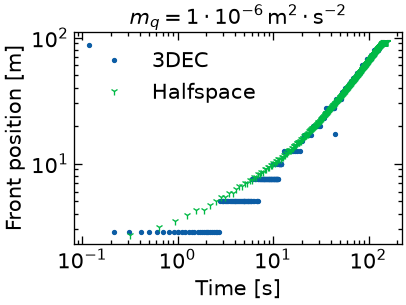

In [3]:
#| echo: false
#| label: fig-comparison-halfspace-3dec
#| fig-cap: Comparison between 3DEC and half-space code results of stress front migration.

fig = plt.figure(
    figsize=(6.4 / 1.5, 4.8 / 1.5), dpi=95, layout="constrained", clear=True, num=1
)
ax = fig.subplots()
ax.plot(result_3dec.t, result_3dec.y, ".", label="3DEC")
ax.plot(result_halfspace.t, result_halfspace.y, "1", label="Halfspace")
ax.set(
    xlabel="Time [s]",
    ylabel="Front position [m]",
    title=rf"$m_q={plotting.sci_latex(run_3dec.params.m_q)}\,\mathrm{{m^2 \cdot s^{{-2}} }}$",
    xscale="log",
    yscale="log",
)
ax.legend(frameon=False)
fig.canvas.draw_idle()
plt.pause(0.01)

## Dimensional self-similarity analysis produces a super-linear late-time scaling exponent for distance ($\alpha=7/5$)

The similarity variables change with the injection condition, so we cannot use the
previously derived variables. Given the nonlinear diffusion equation
$$
	\frac{k_{n}}{12 \mu} \frac{ \partial }{ \partial x } \left(w^{3} \frac{ \partial w }{ \partial x }  \right)  = \frac{ \partial w }{ \partial t } ,
$$ {#eq-diffusion}
and the linearly increasing injection rate

$$
	- \frac{k_{n}}{12 \mu} w^{3} \frac{ \partial w }{ \partial x }  = m_q t,
$$ {#eq-inj-cond}

the dimensionless similarity variables for the soft asymptotic regime are 

$$
    \theta(\zeta) = \frac{w(x,t) - w_{i}}{\left( m_{q}^{2} t^{3} / a \right) ^{1/5}}, \quad \zeta = \frac{x}{\left( a m_{q}^{3} t^{7} \right) ^{1/5}}
$$ {#eq-similarity}

with

$$
    a = \frac{k_{n}}{12 \mu}.
$$

Compared to the constant rate injection, the only things that changed in the
similarity variables is that $q_{0}$ is replaced by $m_{q}$, and the exponents
of times are increased by $3/5$ and $2/5$ for distance and aperture,
respectively. Thus, the similarity variables show the following scaling in time
of distance $x(t) \sim t^{7/5}$ and of aperture $w(t) \sim t^{3/5}$. 

The soft asymptotic limit is reached at large times when $t \gg t_{c}$ with
$t_{c}$ being the characteristic time. At smaller times $t \leq t_{c}$, the
similarity behavior is governed by linear diffusion where distance and aperture
scale proportionally to $t^{1/2}$.

### Derived similarity variables superpose the late-time aperture profiles obtained from a numerical solution

Since I derived the dimensionless variables by hand it would be cautious
to cross-check them with the numerical results of aperture profiles.

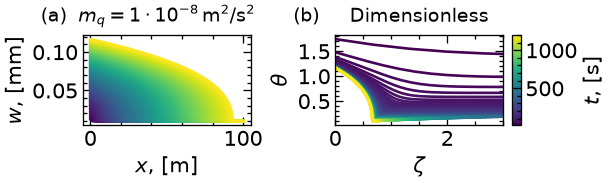

In [4]:
#| echo: false
#| label: fig-similarity
#| fig-cap: Aperture profiles throughout the simulation (a) in dimensional form (b) nondimensionalized with similarity variables for soft asymptotic regime. The dimensionless profiles collapse at late times.


run = io.read_halfspace(paths.results_dir("halfspace", "linear") / "m_q-1e-08.hdf5")

fig = plt.figure(
    figsize=(6.4, 4.8 / 2.5), dpi=95, layout="constrained", clear=True, num=1
)
axes = fig.subplots(1, 2)

sm = plotting.plot_nondimensionalization(
    axes[0], axes[1], run, physics.nondimensionalize_soft, bc="ramp_rate", step=5
)

axes[1].set_xlim(0, 3)
axes[0].set_title(
    rf"$m_q={plotting.sci_latex(run.params.m_q)}\,\mathrm{{m^2 / s^{{2}} }}$",
    fontsize="x-large",
    pad=10,
)
axes[1].set_title("Dimensionless", fontsize="x-large", pad=10)
axes[0].annotate("(a)", (-0.25, 1.15), xycoords="axes fraction", fontsize="x-large")
axes[1].annotate("(b)", (-0.25, 1.15), xycoords="axes fraction", fontsize="x-large")

fig.colorbar(sm, ax=axes, label="$t$, [s]", pad=0.02, aspect=10)

fig.canvas.draw_idle()
plt.pause(0.01)

@fig-similarity shows both dimensional and dimensionless aperture profiles. As expected, at large times when the aperture gradient is significant the dimensionless aperture profiles superpose better than at smaller times.

In [41]:
#| echo: false

result_dir = paths.results_dir("halfspace", "linear")
mq_values = np.geomspace(1e-14, 1e-7, 8)
runs = [io.read_halfspace(result_dir / f"m_q-{m_q:.0e}.hdf5") for m_q in mq_values]
bc = "ramp_rate"

# early runs: keep only the early part (late-time front detection is noisy)
keep_fraction = {0: 1 / 5, 1: 1 / 2, 2: 1 / 2}
results = [
    analysis.analyze_front(
        run,
        stress_front=True,
        slc=slice(int(len(run.t) * keep_fraction.get(i, 1.0))),
    )
    for i, run in enumerate(runs)
]

# pool every run onto dimensionless axes (t / t_c, x_f / x_c)
tc = [physics.characteristic_time(run.params, bc=bc) for run in runs]
xc = [physics.characteristic_distance(run.params, bc=bc) for run in runs]
t_nd = np.concatenate([res.t / t for res, t in zip(results, tc)])
x_nd = np.concatenate([res.y / x for res, x in zip(results, xc)])
positive = t_nd > 0
t_nd, x_nd = t_nd[positive], x_nd[positive]


# fit the crossover to the pooled data: exponents and t_c fixed, (a, b, delta) free
def crossover_fixed_exponents(t, a, b, delta):
    return math_utils.crossover(
        t, a=a, alpha=1 / 2, b=b, beta=7 / 5, x0=1.0, delta=delta
    )


# (a_fit, b_fit, delta_fit), _ = curve_fit(
#      crossover_fixed_exponents, t_nd, x_nd, p0=(1.0, 1.0, 0.5), bounds=(0.0, [10, 10, 10]), maxfev=10_000
# )
# NOTE: because of the outliers the curve_fit overestimated the prefactor a_fit
# visually I found that adjusting the parameters in the following way
# gives a better fit
a_fit = 2.6
b_fit = 1.15
delta_fit = 0.05
print(f"a = {a_fit:.3g}, b = {b_fit:.3g}, delta = {delta_fit:.3g}")

t_range = np.geomspace(t_nd.min(), t_nd.max(), 200)
front_crossover = crossover_fixed_exponents(t_range, a_fit, b_fit, delta_fit)

a = 2.6, b = 1.15, delta = 0.05


### Deriving dimensionless front distance

Using @eq-diffusion and @eq-inj-cond, we can derive the following dimensionless parameters
$$
    w \to \frac{w}{w_{i}}; \quad x \to \frac{x}{x_{c}},\ x_{c} = \left( \frac{a^{2} w_{i}^{7}}{m_{q}} \right)^{1/3}; \quad t \to \frac{t}{t_{c}},\ t_{c} = \frac{x_{c}^{2}}{a w_{i}^{3}} 
$$
where $x_{c}$ and $t_{c}$ are characteristic distance and time, respectively. These characteristic scales can be used to study the evolution of the dimensionless front position across multiple simulations.

## Fitting the crossover function to the numerical data gives $\delta = `{python} float(f"{delta_fit:.2g}")`$

Given that the early-time power-law exponent that describes the migration of
the stress front is 0.5 and the late-time exponent is 1.4 (@eq-similarity),
the crossover function that combines both power-laws separated by $t_{c}$ is
$$
	x_{f}(t) = \frac{A_{\mathrm{early}}t^{0.5}}{1 + (t/t_{c})^{\delta}} + \frac{A_{\mathrm{late}}t^{1.4}}{1 + (t_{c}/t)^{\delta}}.
$$ {#eq-crossover}

I did several numerical simulations (using half-space code) with the slope of
the injection rate condition $m_{q}$ varying in the range
$\mathrm{10^{-14}\,m^2/s^2} \leq m_{q} \leq \mathrm{10^{-7}\,m^2/s^2}$. A
least-squares fit of the crossover function to the pooled dimensionless data
gives $\delta \approx `{python} float(f"{delta_fit:.2g}")`$ (see below
@fig-front). The two asymptotic power-laws are clearly separated by the
dimensionless characteristic time $t_{c} = 1$.

Previously with a constant injection rate condition, I obtained
$\delta=0.01$ and the asymptotic scaling exponents were 0.5 and 0.8. The
results here show that the transition between asymptotic regimes is faster in
the linearly increasing injection rate condition.

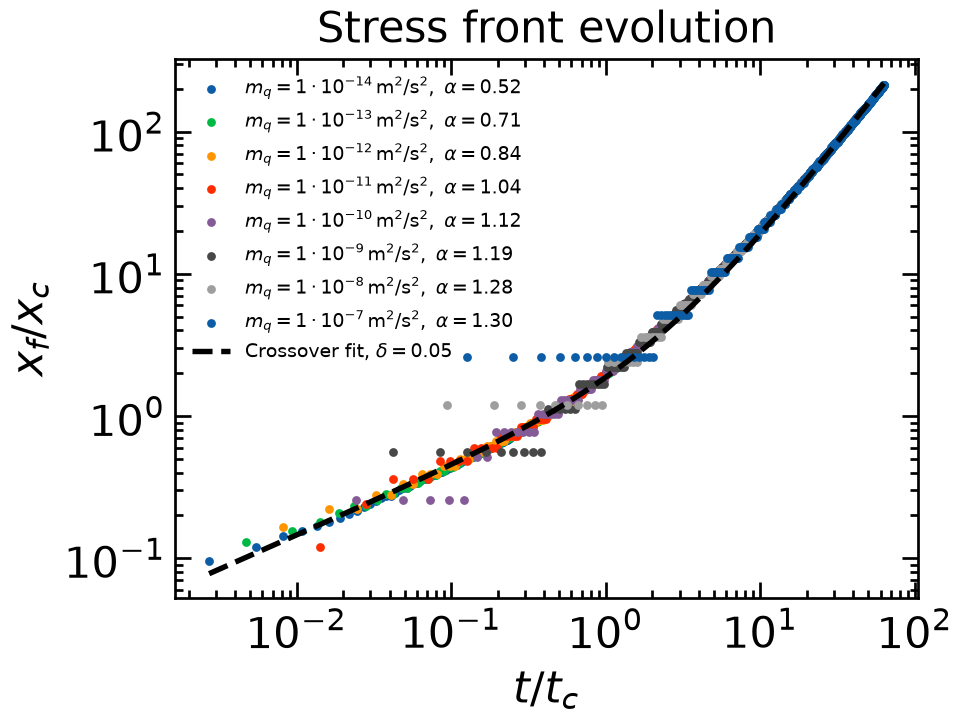

In [42]:
#| echo: false
#| label: fig-front
#| fig-cap: Migration of the dimensionless front across simulations with injection rate ramp $m_q$ varying from $\mathrm{10^{-14}\,m^2/s^2}$ to $\mathrm{10^{-8}\,m^2/s^2}$.

fig = plt.figure(
    figsize=(6.4 / 1.3, 4.8 / 1.3), dpi=195, layout="constrained", clear=True, num=1
)
ax = fig.subplots()
for run, result, t_c, x_c in zip(runs, results, tc, xc):
    label = rf"$m_q={plotting.sci_latex(run.params.m_q)}\,\mathrm{{m^2 / s^2}},\ \alpha = {result.alpha_emp:.2f}$"
    ax.scatter(result.t / t_c, result.y / x_c, s=5, label=label)
ax.plot(
    t_range,
    front_crossover,
    "k--",
    lw=2,
    label=rf"Crossover fit, $\delta={delta_fit:.2g}$",
)
ax.set(
    xlabel=r"$t / t_c$",
    ylabel=r"$x_f / x_c$",
    title="Stress front evolution",
    xscale="log",
    yscale="log",
)
ax.legend(fontsize="x-small", frameon=False)
fig.canvas.draw_idle()
plt.pause(0.01)

## Fitting the crossover function with numerically inferred $\delta$ to the field data reproduces the early- and late-time behaviors in the migration of seismic front

In [58]:
#| echo: false

SECONDS_PER_DAY = 86_400


def to_days(t_sec):
    return t_sec / SECONDS_PER_DAY


# reuse the crossover sharpness found from the numerical simulations
crossover_model = analysis.CrossoverModel(delta=delta_fit)

soultz = analysis.fit_field_crossover(
    *io.load("soultz"),
    title="Soultz 1993",
    percentile=90,
    t_c=3 * SECONDS_PER_DAY,
    model=crossover_model,
)
basel = analysis.fit_field_crossover(
    *io.load("basel"),
    title="Basel 2006",
    percentile=75,
    t_c=2 * SECONDS_PER_DAY,
    model=crossover_model,
)

In [59]:
#| echo: false
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]


def plot_slope_triangle(
    ax: plt.Axes, x: np.ndarray, y: np.ndarray, x0: float, nudge: float = 1
):
    exponent, log_prefactor = np.polyfit(np.log(x), np.log(y), deg=1)
    plotting.slope_triangle(
        ax=ax,
        x0=x0,
        slope=round(exponent, 2),
        prefactor=np.exp(log_prefactor + nudge),
    )


def annotate_regime_slopes(ax: plt.Axes, case: analysis.FieldCase, anchors, nudges):
    """Draw an early- and a late-time slope triangle on the fitted curve."""
    idx_tc = np.searchsorted(case.t_fit, case.t_c)
    halves = [slice(None, idx_tc), slice(idx_tc, None)]
    for slc, i, nudge in zip(halves, anchors, nudges):
        plot_slope_triangle(
            ax,
            to_days(case.t_fit[slc]),
            case.d_fit[slc],
            x0=to_days(float(case.t_fit[i])),
            nudge=nudge,
        )


def annotate_prefactors(ax: plt.Axes, field_case: analysis.FieldCase):
    ax.text(
        0.05,
        0.8,
        rf"$A_{{\mathrm{{early}}}} = {field_case.A_early:.2g} \pm {field_case.perr[0]:.1g},$"
        "\n"
        rf"$A_{{\mathrm{{late}}}} = {field_case.A_late:.2g} \pm {field_case.perr[1]:.1g}$",
        transform=ax.transAxes,
    )


def plot_field_case(ax: plt.Axes, field_case: analysis.FieldCase, **set_kwargs):
    ax.scatter(to_days(field_case.t), field_case.d, color=colors[-1], s=3, alpha=0.5)
    ax.scatter(
        to_days(field_case.t_env),
        field_case.d_env,
        color="k",
        label=f"P{field_case.percentile:g} per {field_case.bin_size} events",
        s=25,
    )
    ax.plot(
        to_days(field_case.t_fit),
        field_case.d_fit,
        color=colors[0],
        lw=3,
        label=rf"Crossover, $\delta={field_case.model.delta:.2g}$",
    )
    ax.axvline(
        to_days(field_case.t_c),
        color="k",
        ls=":",
        label=rf"$t_c=\mathrm{{{to_days(field_case.t_c):.2g}\ days}}$",
    )
    ax.set(
        xlabel="Time [day]", ylabel="Distance [m]", title=field_case.title, **set_kwargs
    )
    ax.spines[["right", "top"]].set_visible(False)
    ax.tick_params(top=False, right=False, which="both")
    ax.legend(loc="lower right", framealpha=1, fontsize="small", frameon=True)

I choose $\delta= `{python} float(f"{delta_fit:.2g}")`$ (inferred from our model) and set characteristic times 
to $t_{c} = 3\, \mathrm{days}$ and $t_{c} = 2\, \mathrm{days}$ for Soultz and
Basel, respectively. I determined $t_{c}$ visually by looking at the
distance-time plots. The effect of $t_{c}$ within the reasonable range is small.
The asymptotic early- and late-time scaling exponents
$\alpha$ are 0.5 and 1.2. I fix the listed parameters in the crossover function
@eq-crossover and optimize early- ($A_{\mathrm{early}}$) and late-time
($A_{\mathrm{late}}$) prefactors to fit the seismic front migration data.
The obtained fit reproduces early- and late-time behaviors. The average
slope of the seicmic front migration in the log-scale before $t_{c}$ is smaller
than after $t_{c}$ in both cases. I denoted the slopes with triangles in
@fig-field. For example, at Soultz, $\alpha\approx 0.5$ when $t<t_{c}$,
$\alpha\approx 0.7$ when $t>t_{c}$. 

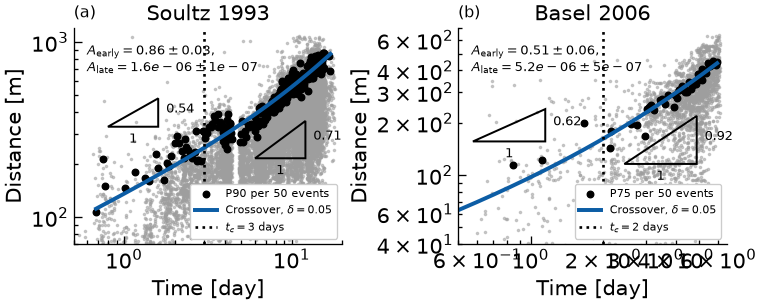

In [60]:
#| echo: false
#| label: fig-field
#| fig-cap: Early- and late-time regimes (average scaling exponents denoted by triangles) shown with the crossover fit to the percentile envelope of the (a) Soultz 1993 and (b) Basel 2006 micro-seismic data.

fig = plt.figure(
    figsize=(6.4 * 1.25, 4.8 / 1.5), dpi=95, layout="constrained", clear=True, num=1
)
ax1, ax2 = fig.subplots(1, 2)

plot_field_case(
    ax1, soultz, xscale="log", yscale="log", xlim=(0.5, 20), ylim=(70, 1200)
)
plot_field_case(ax2, basel, xscale="log", yscale="log", xlim=(0.5, 6.5), ylim=(40, 700))

annotate_regime_slopes(ax1, soultz, anchors=[10, -65], nudges=[1.0, -0.6])
annotate_regime_slopes(ax2, basel, anchors=[70, -50], nudges=[0.8, -0.5])

annotate_prefactors(ax1, soultz)
annotate_prefactors(ax2, basel)

ax1.annotate("(a)", (0, 1.05), xycoords="axes fraction", fontsize="large")
ax2.annotate("(b)", (0, 1.05), xycoords="axes fraction", fontsize="large")

fig.canvas.draw_idle()
plt.pause(0.01)

Previously, we saw that in the constant injection rate case, the scaling
exponent $\alpha$ remains constant within the time-scale of the seismic
migration. There, the transition scale $\delta$ and the late-time scaling
exponent $\alpha$ were smaller. Thus, we did not observe the early- and
late-time behaviors. Equally, the inferred model parameters from the fit were
inconsistent with the reality and the model. The model with linearly increasing
injection rate condition yields more realistic parameters.

## Model parameters inferred from the fit are close to reality except the slope of ramp injection rate $m_{q}$

In [57]:
#| echo: false
D = soultz.A_early**2 / 4
mu = 1e-3
kn_range = np.asarray([1e9, 5000e9])
wi_range = (12 * mu * D / kn_range) ** (1 / 3)
mq_range = (12 * mu * soultz.A_late**5 / kn_range) ** (1 / 3)

print("m_q range", mq_range)

m_q range [5.00455274e-14 2.92668020e-15]


I compare the dimensionless similarity variables @eq-similarity with the
empirical power-law fits to infer the parameters of the model. I start with the
Soultz case. At small times $t \ll t_{c}$, crossover function can be
approximated as $x_{f} = A_{\mathrm{early}} t^{1/2}$ and the analytical
prediction is $x_{f}=(4Dt)^{1/2}$. Equalizing the two gives

$$
    (4Dt)^{1/2} = A_{\mathrm{early}} t^{1/2} 
$$

solving for $D$ gives

$$
    D = \frac{A_{\mathrm{early}}^{2}}{4}
$$

given that $A_{\mathrm{early}} = `{python} round(soultz.A_early, 2)`\,
\mathrm{m/s^{1/2}}$, I find

$$
    D = `{python} round(D, 2)` \, \mathrm{m^2/s}.
$$

We also know for a rigid pre-existing planar fracture that obeys cubic
law for flow and has an initial aperture $w_{i}$, constant normal stiffness
$k_{n}$, and incompressible water with viscosity $\mu$, the hydraulic
diffusivity $D$ equals

$$
    D = \frac{k_{n} w_{i}^{3}}{12 \mu}.
$$

At ambient condition, the water has $\mu=\mathrm{1\, mPa \cdot s}$. The
realistic range of normal stiffness values is $\mathrm{1\,GPa/m} \leq k_{n}
\leq  \mathrm{5000\,GPa/m}$. Given these values and the inferred diffusivity
$D$, we can find the initial aperture

$$
    w_{i} = \left( \frac{12 \mu D}{k_{n}} \right)^{1/3}
$$

to be in the range

$$
`{python} float(f"{wi_range[1]*1e6:.2g}")`\, \mathrm{\mu m} \leq w_{i} \leq
`{python} float(f"{wi_range[0]*1e6:.2g}")`\, \mathrm{\mu m},
$$

which is an acceptable range of values for $w_{i}$.

Given the normal stiffness range, we can find the range for the slope of
linearly increasing injection rate $m_q$ by comparing the empirical late-time
prefactor ($A_{\mathrm{late}}$) with asymptotic late-time prefactor for front
migration (@eq-similarity). Equalizing the empirical and analytical prediction

$$
  \left( \frac{k_{n}}{12 \mu} \right)^{1/5}  m_{q}^{3/5} t^{7/5} = A_{\mathrm{late}} t^{7/5}
$$

yields the following expression for $m_{q}$:

$$
    m_{q} = \left( \frac{12 \mu A_{\mathrm{late}}^{5}}{k_{n}} \right)^{1/3}.
$$

The late-time prefactor is $A_{\mathrm{late}} = `{python} float(f"{soultz.A_late:.2g}")`\, \mathrm{m / s^{1.2}}$. Together with the normal stiffness range, I find

$$
`{python} float(f"{mq_range[0]:.2g}")`\, \mathrm{m^{2}/s^{2}} \leq m_{q} \leq
`{python} float(f"{mq_range[1]:.2g}")`\, \mathrm{m^{2}/s^{2}},
$$

At the moment I do not have the hydraulic data of Soultz 1993 stimulation but I
estimate from the injection history graphs that the slope of linearly
increasing volumetric injection rate is roughly

$$
    m_{Q} \approx \mathrm{10^{-8} \, m^{3}/s^{2}}.
$$

Notice the unit of $m_{Q}$, since it is a volumetric flow rate, it does not
directly compare with $m_{q}$.

## Discussions

### Distance-time plot in linear scale alongside with a square-root law fit

In [50]:
#| echo: false
soultz = analysis.fit_field_crossover(
    *io.load("soultz"),
    title="Soultz 1993",
    percentile=90,
    t_c=3 * SECONDS_PER_DAY,
    model=crossover_model,
    eval_based_envelope=False,
)
basel = analysis.fit_field_crossover(
    *io.load("basel"),
    title="Basel 2006",
    percentile=75,
    t_c=2 * SECONDS_PER_DAY,
    model=crossover_model,
    eval_based_envelope=False,
)

A_soultz_sqrt = math_utils.fit_power_law_fixed_exponent(
    soultz.t_env, soultz.d_env, exponent=0.5
)
A_basel_sqrt = math_utils.fit_power_law_fixed_exponent(
    basel.t_env, basel.d_env, exponent=0.5
)

r_squared_sqrt_soultz = math_utils.compute_r_squared(
    soultz.d_env, math_utils.power_law(t=soultz.t_env, A=A_soultz_sqrt, alpha=0.5)
)
r_squared_sqrt_basel = math_utils.compute_r_squared(
    basel.d_env, math_utils.power_law(t=basel.t_env, A=A_basel_sqrt, alpha=0.5)
)

@fig-field-linear is @fig-field in linear scale alongside with a fit of a
square-root law. Linear scale plot further highlights the square root migration
behavior for small times and the acceleration of seismicity with time at
Soultz. And, at Basel the apparent fit is a migration linear in time. In both
cases, $R^{2}$ measure shows that crossover function is a better fit than the
square root law.

> [!Note]
> $R^{2}$ is meant for
> linear trends rather than power-law fits. However, it is still useful
> for a comparison of goodness-of-fit between two power laws.

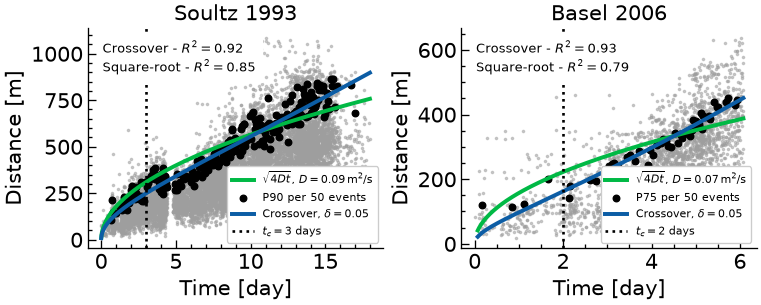

In [51]:
#| echo: false
#| label: fig-field-linear
#| fig-cap: Linear scale distance-time plot of micro-seismicity at (a) Soultz 1993 and (b) Basel 2006. In both cases, crossover function with fixed exponents better fits the seismic envelope than the square root law.

fig = plt.figure(
    figsize=(6.4 * 1.25, 4.8 / 1.5), dpi=95, layout="constrained", clear=True, num=1
)
ax1, ax2 = fig.subplots(1, 2)

ax1.plot(
    to_days(soultz.t_fit),
    math_utils.power_law(soultz.t_fit, A_soultz_sqrt, alpha=0.5),
    color=colors[1],
    lw=3,
    label=rf"$\sqrt{{4Dt}},\, D={A_soultz_sqrt**2 / 4:.1g}\,\mathrm{{m^2/s}}$",
)
ax2.plot(
    to_days(basel.t_fit),
    math_utils.power_law(basel.t_fit, A_basel_sqrt, alpha=0.5),
    color=colors[1],
    lw=3,
    label=rf"$\sqrt{{4Dt}},\, D={A_basel_sqrt**2 / 4:.1g}\,\mathrm{{m^2/s}}$",
)
plot_field_case(ax1, soultz)
plot_field_case(ax2, basel)

ax1.text(
    0.05,
    0.8,
    rf"Crossover - $R^{{2}}= {soultz.r_squared:.2g}$"
    "\n"
    rf"Square-root - $R^{{2}}= {r_squared_sqrt_soultz:.2g}$",
    transform=ax1.transAxes,
    backgroundcolor="1",
)
ax2.text(
    0.05,
    0.8,
    rf"Crossover - $R^{{2}}= {basel.r_squared:.2g}$"
    "\n"
    rf"Square-root - $R^{{2}}= {r_squared_sqrt_basel:.2g}$",
    transform=ax2.transAxes,
    backgroundcolor="1",
)


fig.canvas.draw_idle()
plt.pause(0.01)

One factor that may impact my analysis may be significant is the way I determine
the seismic envelope. Until now, it was based on non-overlapping bins along the
distance array. It is worth to check how the seismic envelope would be affected
if it were detected differently.

### Effect of seismic envelope detection algorithm

To find the seismic front the seismicity data, I divide the seismicity data
(sorted in time) into given number of bins. From each bin I find
the distance value at a given percentile, and I indentify the time value
that is associated with that distance value. The code snippet below
is part of the algorighm:

```python
d_bins = distance[:n_trim].reshape(n_bins, bin_size)  # type: ignore
p_vals = np.percentile(d_bins, percentile, axis=1)  # type: ignore
```

Because seismicity rate changes with time, equal-count bins do not correspond
to equal time windows. Bins covering sparse early periods span wide time
intervals, spreading the resulting envelope points, while bins falling in dense
periods span very short time intervals, producing many closely-spaced points.
Thus, the seismic front derived this way is influenced by the local seismicity
rate. This motivates trying an approach that adapts to local event density
instead of a fixed event count.

For this, we can use a sliding window that is bounded by two parameters: one is
`min_events`, and the other is `max_dt`. Time window size increases until the
given number `min_events` is reached and it is capped by given time `max_dt`.

In [52]:
#| echo: false
t_s, d_s = io.load("soultz")
t_s_env, d_s_env = detection.seismic_envelope(
    t_data=t_s,
    d_data=d_s,
    percentile=90,
    min_events=100,
    max_dt=0.5 * SECONDS_PER_DAY,
    n_eval=1000,
)

The plot below shows how more points are picked at sparse regions (very early
and late during the sequence) compared to @fig-field. But, visually the overall
shape of the seismic envelope is similar.

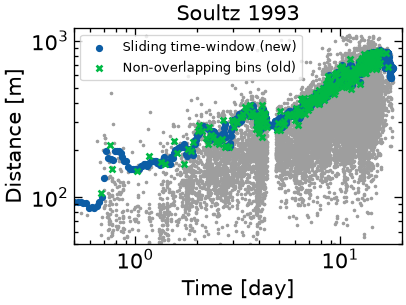

In [53]:
#| echo: false
#| label: fig-field-new-envelope
#| fig-cap: Distance-time plot of Soultz seismicity sequence in log-scale. Seismic front determined by an algorithm that uses a sliding time-window and adapts to local seismicity rate

fig = plt.figure(
    figsize=(6.4 / 1.5, 4.8 / 1.5), dpi=95, layout="constrained", clear=True, num=1
)
ax = fig.subplots()
ax.scatter(to_days(t_s), d_s, color=colors[-1], s=3)
ax.scatter(to_days(t_s_env), d_s_env, s=20, label="Sliding time-window (new)")
ax.scatter(
    to_days(soultz.t_env),
    soultz.d_env,
    s=20,
    marker="x",
    label="Non-overlapping bins (old)",
)
ax.set(
    xlabel="Time [day]",
    ylabel="Distance [m]",
    title="Soultz 1993",
    xscale="log",
    yscale="log",
    xlim=(0.5, 20),
    ylim=(50, 1200),
)
ax.legend(frameon=True, fontsize="medium")
fig.canvas.draw_idle()
plt.pause(0.01)

### Effect of the choice of spatial origin

In all the distance-time plots I picked the spatial origin as
the median position of first ten events.

```python
x0, y0, z0 = x.iloc[:10].median(), y.iloc[:10].median(), z.iloc[:10].median()  # type: ignore
```
The seismicity migration trend may differ if the spatial origin is the
coordinate of where the fluid is injected, i.e. the open hole section of the
borehole. Unfortunately, I couldn't find the coordinates for this point.